In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.utils import class_weight
import numpy as np
import matplotlib.pyplot as plt


In [1]:
   !cd
   !dir

C:\Users\acer\navvtic\brain tumor
 Volume in drive C has no label.
 Volume Serial Number is D8F6-4574

 Directory of C:\Users\acer\navvtic\brain tumor

10/13/2026  10:44 PM    <DIR>          .
10/13/2026  10:44 PM    <DIR>          ..
08/23/2026  02:29 AM                43  .gitignore
08/23/2026  02:26 AM    <DIR>          .ipynb_checkpoints
08/15/2026  10:47 AM        15,828,590 archive (2)-Copy1.zip
10/13/2026  10:44 PM         1,082,416 braintumir.ipynb
08/15/2026  10:52 AM    <DIR>          no
08/23/2026  02:17 AM    <DIR>          yes
               3 File(s)     16,911,049 bytes
               5 Dir(s)  13,664,714,752 bytes free


In [2]:
import os
print(os.listdir("brain tumor"))

['.ipynb_checkpoints', 'archive (2)-Copy1.zip', 'no', 'Untitled.ipynb', 'yes']


In [2]:
  !type .gitignore

The system cannot find the file specified.


In [3]:
dataset_path = "brain tumor"

print(os.listdir(dataset_path + "/yes")[:5])
print(os.listdir(dataset_path + "/no")[:5])



['Y1.jpg', 'Y100.JPG', 'Y101.jpg', 'Y102.jpg', 'Y103.jpg']
['1 no.jpeg', '10 no.jpg', '11 no.jpg', '12 no.jpg', '13 no.jpg']


In [4]:
import os
from PIL import Image
import hashlib

folders = ["brain tumor/yes", "brain tumor/no"]

for folder in folders:
    print(f"\n===== Checking: {folder} =====")
    
    corrupt_files = []
    sizes = []
    hashes = {}
    duplicates = []

    for fname in os.listdir(folder):
        path = os.path.join(folder, fname)

        # 1. Corrupted file check — try opening + verifying the image
        try:
            img = Image.open(path)
            img.verify()
        except Exception:
            corrupt_files.append(fname)
            continue  # skip further checks on broken files

        # 2. Size/format check — reopen (verify() closes the file) and record dimensions
        img = Image.open(path)
        sizes.append(img.size)

        # 3. Duplicate check — hash file content, compare against seen hashes
        with open(path, 'rb') as f:
            file_hash = hashlib.md5(f.read()).hexdigest()
        if file_hash in hashes:
            duplicates.append((fname, hashes[file_hash]))
        else:
            hashes[file_hash] = fname

    # Results
    print("Corrupted files:", corrupt_files)
    print("Unique image sizes found:", set(sizes))
    print("Duplicate files:", duplicates)
    print("Total images:", len(os.listdir(folder)))




===== Checking: brain tumor/yes =====
Corrupted files: []
Unique image sizes found: {(300, 325), (311, 355), (254, 312), (232, 309), (283, 357), (204, 247), (206, 244), (205, 246), (189, 173), (289, 315), (278, 324), (297, 359), (1061, 1280), (1059, 1200), (201, 251), (300, 336), (283, 295), (246, 310), (321, 352), (911, 938), (264, 336), (290, 355), (272, 350), (294, 380), (197, 255), (433, 520), (1275, 1427), (283, 334), (213, 236), (215, 233), (281, 352), (224, 245), (204, 251), (620, 620), (264, 338), (300, 359), (320, 355), (278, 349), (306, 365), (355, 450), (223, 303), (260, 331), (258, 279), (205, 243), (291, 340), (293, 337), (504, 630), (456, 519), (283, 338), (781, 960), (278, 351), (374, 456), (273, 318), (236, 278), (256, 256), (310, 355), (467, 586), (587, 630), (241, 286), (1024, 1024), (225, 225), (272, 331), (300, 347), (254, 325), (319, 360), (310, 366), (216, 234), (271, 307), (289, 300), (279, 354), (200, 210), (272, 324), (450, 446), (300, 349), (197, 256), (229, 

In [4]:
   %%writefile .gitignore
   yes/
   no/
   *.zip
   *.h5
   .ipynb_checkpoints/

Writing .gitignore


In [5]:
   import os
   print(os.listdir())
   print(open(".gitignore").read())

[' .gitignore', '.git', '.gitignore', '.ipynb_checkpoints', 'archive (2)-Copy1.zip', 'braintumir.ipynb', 'no', 'yes']
yes/
no/
*.zip
*.h5
.ipynb_checkpoints/



In [5]:
import os

# From the pairs found earlier, keep the FIRST name, remove the duplicate (second name)
duplicates = [('Y162.jpg','Y108.jpg'), ('Y169.jpg','Y13.jpg'), ('Y181.jpg','Y15.jpg'),
              ('Y33.jpg','Y107.jpg'), ('Y34.jpg','Y15.jpg'), ('Y37.jpg','Y10.jpg'),
              ('Y38.jpg','Y30.jpg'), ('Y54.jpg','Y30.jpg'), ('Y62.jpg','Y31.jpg'),
              ('Y69.jpg','Y25.jpg'), ('Y70.jpg','Y30.jpg'), ('Y74.jpg','Y55.jpg'),
              ('Y79.jpg','Y154.jpg')]  # paste your full list from the output here

folder = "brain tumor/yes"

for keep, remove in duplicates:
    remove_path = os.path.join(folder, remove)
    if os.path.exists(remove_path):
        os.remove(remove_path)
        print(f"Removed duplicate: {remove}")

print("Remaining images:", len(os.listdir(folder)))



Remaining images: 145


In [6]:
import os
os.remove(" .gitignore")
print(os.listdir())

['.git', '.gitignore', '.ipynb_checkpoints', 'archive (2)-Copy1.zip', 'braintumir.ipynb', 'no', 'yes']


In [7]:
!git status

On branch main
Changes not staged for commit:
  (use "git add/rm <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	deleted:     .gitignore
	modified:   braintumir.ipynb

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	.gitignore

no changes added to commit (use "git add" and/or "git commit -a")


In [8]:
!git remote -v

origin	https://github.com/fatimahaya0011/brain-tumor-prediction-CNN-.git (fetch)
origin	https://github.com/fatimahaya0011/brain-tumor-prediction-CNN-.git (push)


In [9]:
!git log --oneline

c0150ac Initial commit: brain tumor MRI classifier


In [10]:
!git ls-files

 .gitignore
.ipynb_checkpoints/ -checkpoint.gitignore
.ipynb_checkpoints/braintumir-checkpoint.ipynb
archive (2)-Copy1.zip
braintumir.ipynb
no/1 no.jpeg
no/10 no.jpg
no/11 no.jpg
no/12 no.jpg
no/13 no.jpg
no/14 no.jpg
no/15 no.jpg
no/17 no.jpg
no/18 no.jpg
no/19 no.jpg
no/2 no.jpeg
no/20 no.jpg
no/21 no.jpg
no/22 no.jpg
no/23 no.jpg
no/24 no.jpg
no/25 no.jpg
no/26 no.jpg
no/27 no.jpg
no/28 no.jpg
no/29 no.jpg
no/3 no.jpg
no/30 no.jpg
no/31 no.jpg
no/32 no.jpg
no/33 no.jpg
no/34 no.jpg
no/35 no.jpg
no/36 no.jpg
no/37 no.jpg
no/38 no.jpg
no/39 no.jpg
no/4 no.jpg
no/40 no.jpg
no/41 no.jpg
no/42 no.jpg
no/43 no.jpg
no/44no.jpg
no/45 no.jpg
no/46 no.jpg
no/47 no.jpg
no/48 no.jpeg
no/49 no.jpg
no/5 no.jpg
no/50 no.jpg
no/6 no.jpg
no/7 no.jpg
no/8 no.jpg
no/9 no.jpg
no/N1.JPG
no/N11.jpg
no/N15.jpg
no/N16.jpg
no/N17.jpg
no/N19.JPG
no/N2.JPG
no/N20.JPG
no/N21.jpg
no/N22.JPG
no/N26.JPG
no/N3.jpg
no/N5.jpg
no/N6.jpg
no/No11.jpg
no/No12.jpg
no/No13.jpg
no/No14.jpg
no/No15.jpg
no/No16.jpg
no/No17.j

In [11]:
!git add .

In [12]:
!git commit -m "Fix gitignore and update notebook"

[main 8ce63dd] Fix gitignore and update notebook
 3 files changed, 200 insertions(+), 1 deletion(-)
 delete mode 100644  .gitignore
 create mode 100644 .gitignore


In [14]:
!git push -u origin main

branch 'main' set up to track 'origin/main'.


Everything up-to-date


In [15]:
!git rm -r --cached --ignore-unmatch no yes .ipynb_checkpoints

rm '.ipynb_checkpoints/ -checkpoint.gitignore'
rm '.ipynb_checkpoints/braintumir-checkpoint.ipynb'
rm 'no/1 no.jpeg'
rm 'no/10 no.jpg'
rm 'no/11 no.jpg'
rm 'no/12 no.jpg'
rm 'no/13 no.jpg'
rm 'no/14 no.jpg'
rm 'no/15 no.jpg'
rm 'no/17 no.jpg'
rm 'no/18 no.jpg'
rm 'no/19 no.jpg'
rm 'no/2 no.jpeg'
rm 'no/20 no.jpg'
rm 'no/21 no.jpg'
rm 'no/22 no.jpg'
rm 'no/23 no.jpg'
rm 'no/24 no.jpg'
rm 'no/25 no.jpg'
rm 'no/26 no.jpg'
rm 'no/27 no.jpg'
rm 'no/28 no.jpg'
rm 'no/29 no.jpg'
rm 'no/3 no.jpg'
rm 'no/30 no.jpg'
rm 'no/31 no.jpg'
rm 'no/32 no.jpg'
rm 'no/33 no.jpg'
rm 'no/34 no.jpg'
rm 'no/35 no.jpg'
rm 'no/36 no.jpg'
rm 'no/37 no.jpg'
rm 'no/38 no.jpg'
rm 'no/39 no.jpg'
rm 'no/4 no.jpg'
rm 'no/40 no.jpg'
rm 'no/41 no.jpg'
rm 'no/42 no.jpg'
rm 'no/43 no.jpg'
rm 'no/44no.jpg'
rm 'no/45 no.jpg'
rm 'no/46 no.jpg'
rm 'no/47 no.jpg'
rm 'no/48 no.jpeg'
rm 'no/49 no.jpg'
rm 'no/5 no.jpg'
rm 'no/50 no.jpg'
rm 'no/6 no.jpg'
rm 'no/7 no.jpg'
rm 'no/8 no.jpg'
rm 'no/9 no.jpg'
rm 'no/N1.JPG'
rm 'no/N11.

In [16]:
!git rm --cached --ignore-unmatch "archive (2)-Copy1.zip"

rm 'archive (2)-Copy1.zip'


In [17]:
!git commit -m "Stop tracking dataset and checkpoints"

[main 16da829] Stop tracking dataset and checkpoints
 248 files changed, 1206 deletions(-)
 delete mode 100644 .ipynb_checkpoints/ -checkpoint.gitignore
 delete mode 100644 .ipynb_checkpoints/braintumir-checkpoint.ipynb
 delete mode 100644 archive (2)-Copy1.zip
 delete mode 100644 no/1 no.jpeg
 delete mode 100644 no/10 no.jpg
 delete mode 100644 no/11 no.jpg
 delete mode 100644 no/12 no.jpg
 delete mode 100644 no/13 no.jpg
 delete mode 100644 no/14 no.jpg
 delete mode 100644 no/15 no.jpg
 delete mode 100644 no/17 no.jpg
 delete mode 100644 no/18 no.jpg
 delete mode 100644 no/19 no.jpg
 delete mode 100644 no/2 no.jpeg
 delete mode 100644 no/20 no.jpg
 delete mode 100644 no/21 no.jpg
 delete mode 100644 no/22 no.jpg
 delete mode 100644 no/23 no.jpg
 delete mode 100644 no/24 no.jpg
 delete mode 100644 no/25 no.jpg
 delete mode 100644 no/26 no.jpg
 delete mode 100644 no/27 no.jpg
 delete mode 100644 no/28 no.jpg
 delete mode 100644 no/29 no.jpg
 delete mode 100644 no/3 no.jpg
 delete mode 

In [18]:
!git push

To https://github.com/fatimahaya0011/brain-tumor-prediction-CNN-.git
   8ce63dd..16da829  main -> main


In [19]:
   !git ls-files

.gitignore
braintumir.ipynb


In [20]:
   !cd

C:\Users\acer\navvtic\brain tumor


In [21]:
!rmdir /s /q .git

In [22]:
!git init

Initialized empty Git repository in C:/Users/acer/navvtic/brain tumor/.git/


In [23]:
!git add .

In [24]:
!git status

On branch master

No commits yet

Changes to be committed:
  (use "git rm --cached <file>..." to unstage)
	new file:   .gitignore
	new file:   braintumir.ipynb

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   braintumir.ipynb



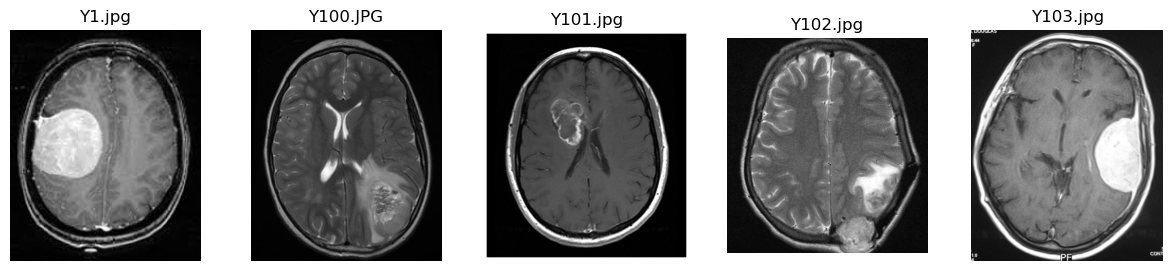

In [6]:
import matplotlib.pyplot as plt
from PIL import Image
import os

fig, axes = plt.subplots(1, 5, figsize=(15,3))
for i, fname in enumerate(os.listdir("brain tumor/yes")[:5]):
    img = Image.open(os.path.join("brain tumor/yes", fname))
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(fname)
    axes[i].axis('off')
plt.show()

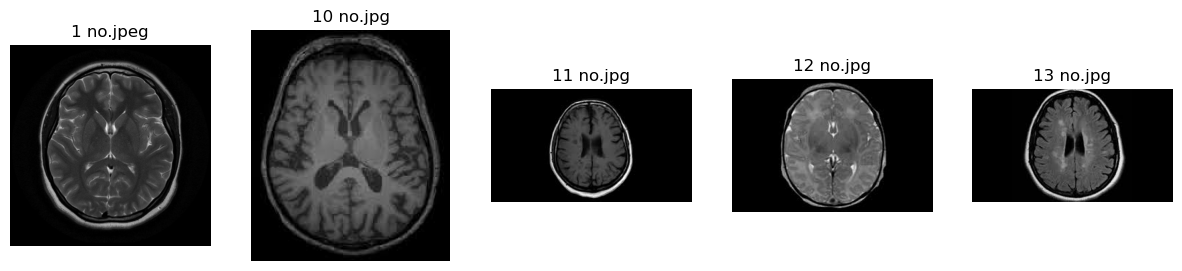

In [7]:
import matplotlib.pyplot as plt
from PIL import Image
import os

fig, axes = plt.subplots(1, 5, figsize=(15,3))
for i, fname in enumerate(os.listdir("brain tumor/no")[:5]):
    img = Image.open(os.path.join("brain tumor/no", fname))
    axes[i].imshow(img, cmap='gray')
    axes[i].set_title(fname)
    axes[i].axis('off')
plt.show()

Found 195 images belonging to 3 classes.
Found 48 images belonging to 3 classes.


C:\Users\acer\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 641ms/step - accuracy: 0.3487 - loss: -44.7416 - val_accuracy: 0.3958 - val_loss: -237.4376
Epoch 2/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 574ms/step - accuracy: 0.4051 - loss: -914.1389 - val_accuracy: 0.3958 - val_loss: -3875.8367
Epoch 3/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 628ms/step - accuracy: 0.4051 - loss: -8265.9268 - val_accuracy: 0.3958 - val_loss: -27157.3438
Epoch 4/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 626ms/step - accuracy: 0.4051 - loss: -45244.6602 - val_accuracy: 0.3958 - val_loss: -130143.7266
Epoch 5/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 743ms/step - accuracy: 0.4051 - loss: -208223.5469 - val_accuracy: 0.3958 - val_loss: -445999.1250
Epoch 6/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 644ms/step - accuracy: 0.4051 - loss: -615513.3750 - val_accuracy: 0.3958 - val_loss: -1341620.0000
Epoch 7/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 645ms/step - accuracy: 0.4051 - loss: -1718932.6250 - val_accuracy: 0.3958 - val_loss: -3541234.7500
Epoch 8/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 734ms/st

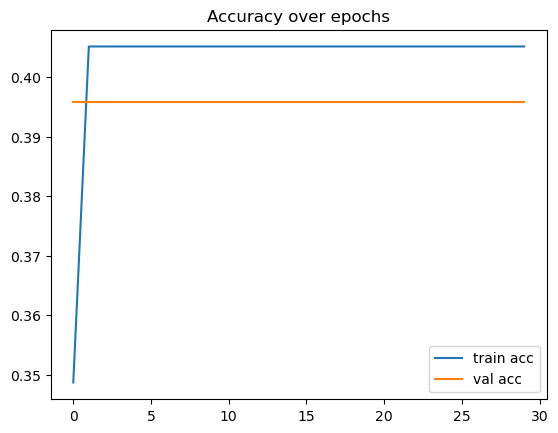

In [8]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

# 1. Load images, resize, normalize pixel values (0-1), split into train/val
datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_data = datagen.flow_from_directory(
    "brain tumor", target_size=(150,150), batch_size=32,
    class_mode='binary', subset='training'
)
val_data = datagen.flow_from_directory(
    "brain tumor", target_size=(150,150), batch_size=32,
    class_mode='binary', subset='validation'
)

# 2. Build CNN — Conv+Pool layers extract features, Dense layers classify
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(150,150,3)),  # detect basic edges/patterns
    MaxPooling2D(2,2),                                              # shrink size, keep key features

    Conv2D(64, (3,3), activation='relu'),                           # detect more complex shapes
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),                          # detect high-level tumor patterns
    MaxPooling2D(2,2),

    Flatten(),                        # convert 2D features to 1D for Dense layers
    Dense(128, activation='relu'),    # learn combinations of features
    Dropout(0.5),                     # randomly turn off neurons to prevent overfitting
    Dense(1, activation='sigmoid')    # output: 0-1 probability (tumor or not)
])

# 3. Compile — set how model learns
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 4. Train — stop early if val_loss stops improving (prevents overfitting on small data)
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(train_data, validation_data=val_data, epochs=30, callbacks=[early_stop])

# 5. Plot accuracy — visually confirm model is learning, not overfitting
plt.plot(history.history['accuracy'], label='train acc')
plt.plot(history.history['val_accuracy'], label='val acc')
plt.legend()
plt.title('Accuracy over epochs')
plt.show()

In [9]:
batch_images, batch_labels = next(train_data)
print("Image shape:", batch_images.shape)
print("Pixel value range:", batch_images.min(), "to", batch_images.max())
print("Sample labels:", batch_labels[:10])

Image shape: (32, 150, 150, 3)
Pixel value range: 0.0 to 1.0
Sample labels: [1. 1. 1. 2. 2. 1. 1. 2. 2. 2.]


In [10]:
import os
print(os.listdir("brain tumor"))

['.ipynb_checkpoints', 'archive (2)-Copy1.zip', 'no', 'Untitled.ipynb', 'yes']


In [13]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_data = datagen.flow_from_directory(
    "brain tumor", target_size=(150,150), batch_size=32,
    class_mode='binary', subset='training'
)
val_data = datagen.flow_from_directory(
    "brain tumor", target_size=(150,150), batch_size=32,
    class_mode='binary', subset='validation'
)

batch_images, batch_labels = next(train_data)
print("Sample labels:", batch_labels[:10])

Found 195 images belonging to 3 classes.
Found 48 images belonging to 3 classes.
Sample labels: [1. 2. 2. 1. 1. 1. 2. 1. 1. 1.]


In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(150,150,3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(train_data, validation_data=val_data, epochs=30, callbacks=[early_stop])

Epoch 1/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 663ms/step - accuracy: 0.3487 - loss: -77.8033 - val_accuracy: 0.3958 - val_loss: -397.7791
Epoch 2/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 4s 583ms/step - accuracy: 0.4051 - loss: -1443.3621 - val_accuracy: 0.3958 - val_loss: -4962.4614
Epoch 3/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 623ms/step - accuracy: 0.4051 - loss: -9354.2432 - val_accuracy: 0.3958 - val_loss: -31962.3496
Epoch 4/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 753ms/step - accuracy: 0.4051 - loss: -56314.7812 - val_accuracy: 0.3958 - val_loss: -134505.8594
Epoch 5/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 648ms/step - accuracy: 0.4051 - loss: -192619.7969 - val_accuracy: 0.3958 - val_loss: -447717.8750
Epoch 6/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 732ms/step - accuracy: 0.4051 - loss: -639043.8125 - val_accuracy: 0.3958 - val_loss: -1263446.8750
Epoch 7/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 784ms/step - accuracy: 0.4051 - loss: -1620059.7500 - val_accuracy: 0.3958 - val_loss: -3142416.2500
Epoch 8/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 686ms/s

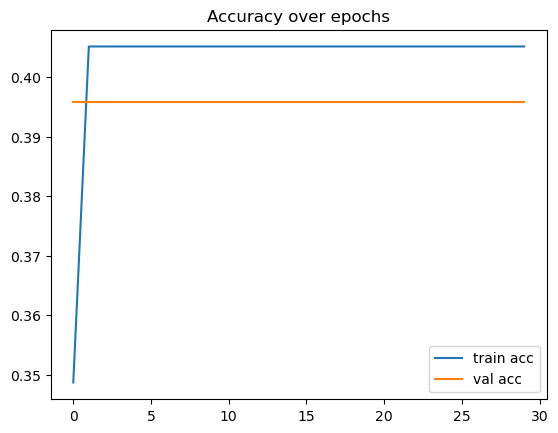

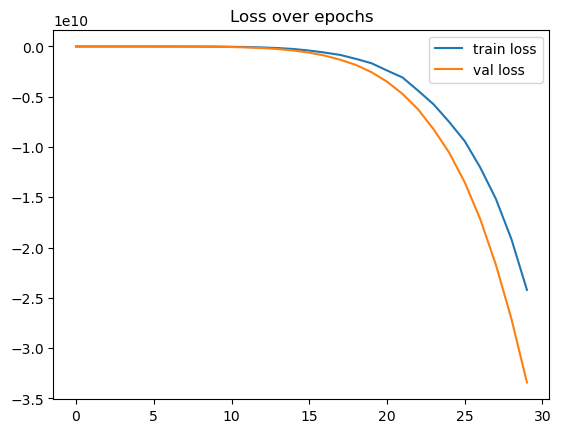

In [16]:


plt.plot(history.history['accuracy'], label='train acc')
plt.plot(history.history['val_accuracy'], label='val acc')
plt.legend()
plt.title('Accuracy over epochs')
plt.show()

plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.legend()
plt.title('Loss over epochs')
plt.show()

In [17]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_data = train_datagen.flow_from_directory(

    
    "brain tumor", target_size=(150,150), batch_size=32,
    class_mode='binary', subset='training'
)
val_data = val_datagen.flow_from_directory(
    "brain tumor", target_size=(150,150), batch_size=32,
    class_mode='binary', subset='validation'
)

Found 195 images belonging to 3 classes.
Found 48 images belonging to 3 classes.


In [18]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

# Logic: Conv+Pool layers extract visual features, Dense layers do the final classification
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(150,150,3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),   # randomly disables neurons during training to reduce overfitting
    Dense(1, activation='sigmoid')  # single output: probability of "tumor"
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
# Logic: EarlyStopping watches val_loss; if it stops improving for 5 epochs straight,
# training stops automatically and restores the BEST version of the model (not the last one)
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=30,
    callbacks=[early_stop]
)

Epoch 1/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 8s 738ms/step - accuracy: 0.3846 - loss: -50.4320 - val_accuracy: 0.3958 - val_loss: -354.0240
Epoch 2/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 725ms/step - accuracy: 0.4051 - loss: -1184.4183 - val_accuracy: 0.3958 - val_loss: -4839.7969
Epoch 3/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 890ms/step - accuracy: 0.4051 - loss: -11533.6631 - val_accuracy: 0.3958 - val_loss: -32218.5078
Epoch 4/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 774ms/step - accuracy: 0.4051 - loss: -53717.8750 - val_accuracy: 0.3958 - val_loss: -139486.6094
Epoch 5/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 875ms/step - accuracy: 0.4051 - loss: -197869.7188 - val_accuracy: 0.3958 - val_loss: -476501.3438
Epoch 6/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 783ms/step - accuracy: 0.4051 - loss: -625704.8750 - val_accuracy: 0.3958 - val_loss: -1448116.3750
Epoch 7/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 747ms/step - accuracy: 0.4051 - loss: -1743706.8750 - val_accuracy: 0.3958 - val_loss: -3790636.0000
Epoch 8/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 728ms/

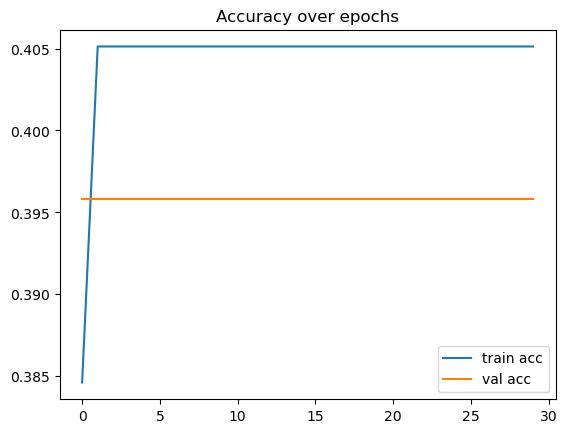

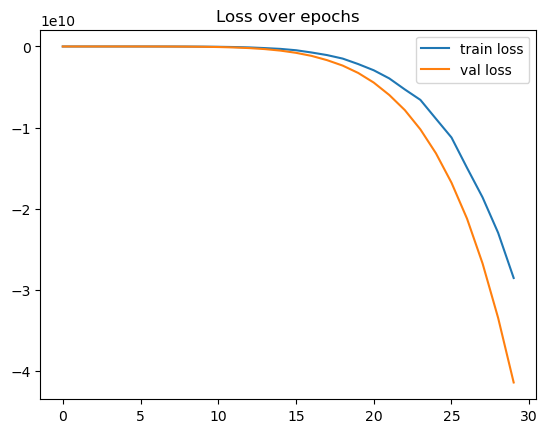

In [20]:
# Concept: visualize both metrics over time to SEE the train/val gap directly
plt.plot(history.history['accuracy'], label='train acc')
plt.plot(history.history['val_accuracy'], label='val acc')
plt.legend()
plt.title('Accuracy over epochs')
plt.show()

plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.legend()
plt.title('Loss over epochs')
plt.show()

In [21]:
!pip install opencv-python

Using layer: conv2d_8


C:\Users\acer\AppData\Local\Temp\ipykernel_14684\2115391299.py:39: RuntimeWarning: invalid value encountered in cast
  heatmap_resized = np.uint8(255 * heatmap_resized)


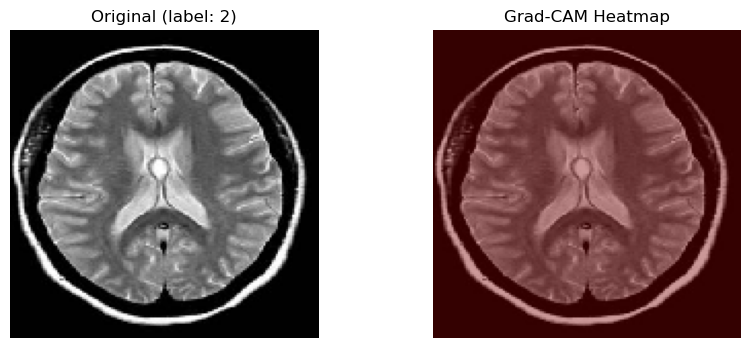

In [25]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2

last_conv_layer_name = None
for layer in model.layers:
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer_name = layer.name
print("Using layer:", last_conv_layer_name)

def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    inputs = tf.keras.Input(shape=(150, 150, 3))
    x = inputs
    conv_output = None
    for layer in model.layers:
        x = layer(x)
        if layer.name == last_conv_layer_name:
            conv_output = x
    grad_model = tf.keras.models.Model(inputs, [conv_output, x])
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        loss = predictions[:, 0]
    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

val_data.reset()
sample_images, sample_labels = next(val_data)
img_array = np.expand_dims(sample_images[0], axis=0)

heatmap = make_gradcam_heatmap(img_array, model, last_conv_layer_name)

heatmap_resized = cv2.resize(heatmap, (150, 150))
heatmap_resized = np.uint8(255 * heatmap_resized)
heatmap_colored = cv2.applyColorMap(heatmap_resized, cv2.COLORMAP_JET)

original_img = np.uint8(255 * sample_images[0])
superimposed_img = cv2.addWeighted(original_img, 0.6, heatmap_colored, 0.4, 0)

fig, axes = plt.subplots(1, 2, figsize=(10,4))
axes[0].imshow(sample_images[0])
axes[0].set_title(f"Original (label: {int(sample_labels[0])})")
axes[0].axis('off')
axes[1].imshow(superimposed_img)
axes[1].set_title("Grad-CAM Heatmap")
axes[1].axis('off')
plt.show()

In [26]:
print(val_data.class_indices)
sample_images, sample_labels = next(val_data)
print(sample_labels[:10])

{'.ipynb_checkpoints': 0, 'no': 1, 'yes': 2}
[2. 2. 1. 1. 2. 2. 1. 1. 2. 1.]


In [27]:
import os, shutil

# Remove the auto-generated checkpoints folder
if os.path.exists("brain tumor/.ipynb_checkpoints"):
    shutil.rmtree("brain tumor/.ipynb_checkpoints")

print(os.listdir("brain tumor"))

['archive (2)-Copy1.zip', 'no', 'Untitled.ipynb', 'yes']


In [28]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True
)
val_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_data = train_datagen.flow_from_directory(
    "brain tumor", target_size=(150,150), batch_size=32,
    class_mode='binary', subset='training'
)
val_data = val_datagen.flow_from_directory(
    "brain tumor", target_size=(150,150), batch_size=32,
    class_mode='binary', subset='validation'
)

print(val_data.class_indices)

Found 195 images belonging to 2 classes.
Found 48 images belonging to 2 classes.
{'no': 0, 'yes': 1}


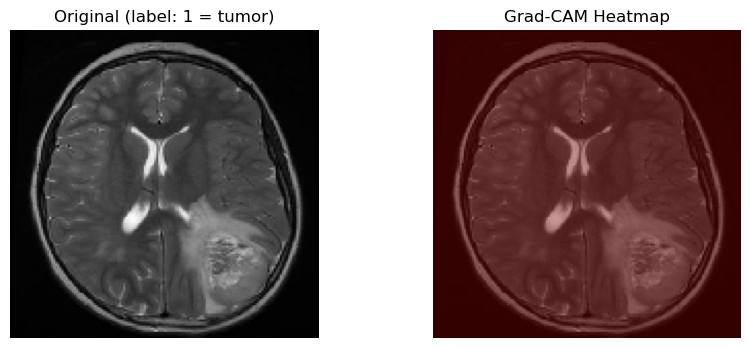

In [29]:
# Find a "yes" (tumor, label=1) image from validation data
val_data.reset()
sample_images, sample_labels = next(val_data)

test_img = None
for i in range(len(sample_labels)):
    if sample_labels[i] == 1:
        test_img = sample_images[i]
        break

img_array = np.expand_dims(test_img, axis=0)
heatmap = make_gradcam_heatmap(img_array, model, last_conv_layer_name)

# nan_to_num prevents crashes if heatmap has any invalid values
heatmap_resized = cv2.resize(heatmap, (150, 150))
heatmap_resized = np.uint8(255 * np.nan_to_num(heatmap_resized))
heatmap_colored = cv2.applyColorMap(heatmap_resized, cv2.COLORMAP_JET)

original_img = np.uint8(255 * test_img)
superimposed_img = cv2.addWeighted(original_img, 0.6, heatmap_colored, 0.4, 0)

fig, axes = plt.subplots(1, 2, figsize=(10,4))
axes[0].imshow(test_img)
axes[0].set_title("Original (label: 1 = tumor)")
axes[0].axis('off')
axes[1].imshow(superimposed_img)
axes[1].set_title("Grad-CAM Heatmap")
axes[1].axis('off')
plt.show()